# BÀI 2: PHÂN LỚP DỮ LIỆU MNIST BẰNG NEURAL NETWORK


## Chuẩn bị thư viện

In [17]:
print("NguyenDucTinh - 6451071077")
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

NguyenDucTinh - 6451071077


## Câu a: Đọc bộ dữ liệu MNIST từ Keras

In [18]:
print("NguyenDucTinh - 6451071077")
# load_data() trả về tập train và tập test có sẵn
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

print("Đọc dữ liệu MNIST thành công!")
print("Train images:", train_images.shape)
print("Train labels:", train_labels.shape)
print("Test images:", test_images.shape)
print("Test labels:", test_labels.shape)

NguyenDucTinh - 6451071077
Đọc dữ liệu MNIST thành công!
Train images: (60000, 28, 28)
Train labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## Câu b: In kích thước tập train và test

In [19]:
print("NguyenDucTinh - 6451071077")
print("Kích thước train_images:", train_images.shape)
print("Kích thước train_labels:", train_labels.shape)
print("Kích thước test_images:", test_images.shape)
print("Kích thước test_labels:", test_labels.shape)

NguyenDucTinh - 6451071077
Kích thước train_images: (60000, 28, 28)
Kích thước train_labels: (60000,)
Kích thước test_images: (10000, 28, 28)
Kích thước test_labels: (10000,)


## Câu c: Chuẩn hóa giá trị pixel về đoạn [0, 1]

In [20]:
print("NguyenDucTinh - 6451071077")
# Pixel ban đầu có giá trị từ 0 đến 255.
# Chuyển sang float32 và chia 255.0 để đưa về [0, 1].
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

print("Giá trị pixel nhỏ nhất của train:", train_images.min())
print("Giá trị pixel lớn nhất của train:", train_images.max())
print("Giá trị pixel nhỏ nhất của test:", test_images.min())
print("Giá trị pixel lớn nhất của test:", test_images.max())

NguyenDucTinh - 6451071077


Giá trị pixel nhỏ nhất của train: 0.0
Giá trị pixel lớn nhất của train: 1.0
Giá trị pixel nhỏ nhất của test: 0.0
Giá trị pixel lớn nhất của test: 1.0


## Câu d: Chia tập train ban đầu thành train và validation theo tỷ lệ 8:2

In [21]:
print("NguyenDucTinh - 6451071077")
# Giữ nguyên 10.000 ảnh test của MNIST.
# Chia 60.000 ảnh train ban đầu thành 48.000 train và 12.000 validation.
train_images, validation_images, train_labels, validation_labels = train_test_split(
    train_images,
    train_labels,
    test_size=0.2,
    random_state=42,
    stratify=train_labels
)

print("Kích thước tập train:", train_images.shape, train_labels.shape)
print("Kích thước tập validation:", validation_images.shape, validation_labels.shape)
print("Kích thước tập test:", test_images.shape, test_labels.shape)

NguyenDucTinh - 6451071077
Kích thước tập train: (48000, 28, 28) (48000,)
Kích thước tập validation: (12000, 28, 28) (12000,)
Kích thước tập test: (10000, 28, 28) (10000,)


## Câu e: Xây dựng Neural Network

In [22]:
print("NguyenDucTinh - 6451071077")
# Mô hình gồm:
# 1. Flatten: chuyển ảnh 28x28 thành vector 784 chiều.
# 2. Dense: 128 neuron, hàm kích hoạt ReLU.
# 3. Dropout: tắt ngẫu nhiên 20% neuron khi huấn luyện.
# 4. Dense: 10 neuron đầu ra, Softmax cho 10 chữ số (0-9).

model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(10, activation="softmax")
])

model.summary()

NguyenDucTinh - 6451071077


c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Câu f: Biên dịch mô hình

In [23]:
print("NguyenDucTinh - 6451071077")
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Biên dịch mô hình thành công!")

NguyenDucTinh - 6451071077
Biên dịch mô hình thành công!


## Câu g: Huấn luyện mô hình và đánh giá trên validation

In [24]:
print("NguyenDucTinh - 6451071077")
history = model.fit(
    train_images,
    train_labels,
    epochs=5,
    batch_size=32,
    validation_data=(validation_images, validation_labels),
    verbose=1
)

NguyenDucTinh - 6451071077
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9056 - loss: 0.3259 - val_accuracy: 0.9526 - val_loss: 0.1676
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9541 - loss: 0.1555 - val_accuracy: 0.9635 - val_loss: 0.1236
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9652 - loss: 0.1187 - val_accuracy: 0.9706 - val_loss: 0.0997
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9708 - loss: 0.0949 - val_accuracy: 0.9728 - val_loss: 0.0903
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9757 - loss: 0.0786 - val_accuracy: 0.9727 - val_loss: 0.0878


## Câu h: Vẽ biểu đồ Accuracy và Loss sau mỗi epoch

NguyenDucTinh - 6451071077


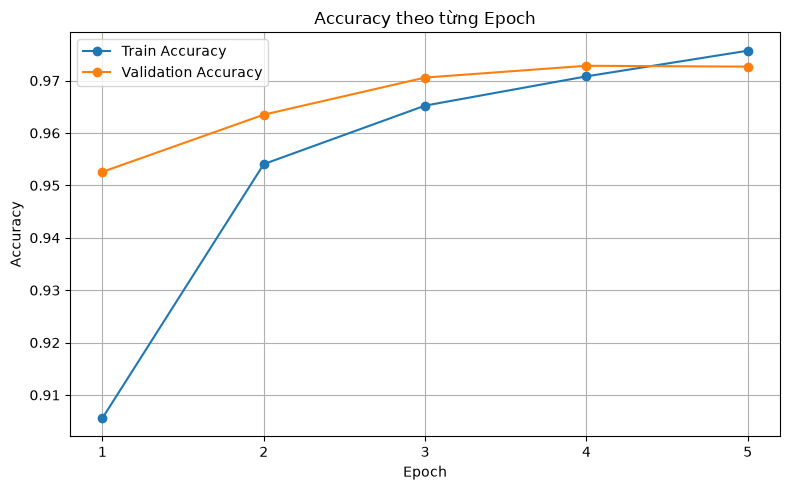

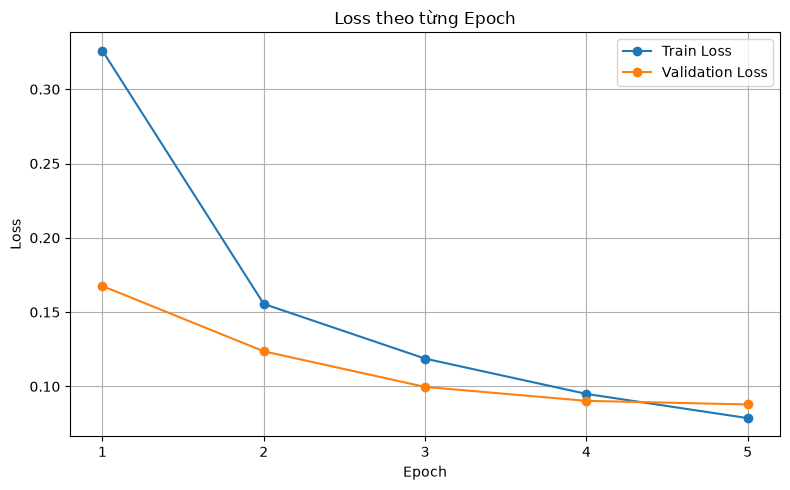

In [25]:
print("NguyenDucTinh - 6451071077")
epochs_range = range(1, len(history.history["accuracy"]) + 1)

# Biểu đồ Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["accuracy"], marker="o", label="Train Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Accuracy theo từng Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Biểu đồ Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["loss"], marker="o", label="Train Loss")
plt.plot(epochs_range, history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Loss theo từng Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Câu i: Dự đoán phân lớp cho tập test

In [26]:
print("NguyenDucTinh - 6451071077")
# predict() trả về xác suất của từng ảnh thuộc 10 class.
y_prob = model.predict(test_images, verbose=1)

# argmax(axis=1) lấy class có xác suất lớn nhất ở mỗi ảnh.
y_pred = np.argmax(y_prob, axis=1)

print("5 nhãn dự đoán đầu tiên:", y_pred[:5])
print("5 nhãn thực tế đầu tiên:", test_labels[:5])

NguyenDucTinh - 6451071077
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 640us/step
5 nhãn dự đoán đầu tiên: [7 2 1 0 4]
5 nhãn thực tế đầu tiên: [7 2 1 0 4]


## Câu j: Tính và in Accuracy trên tập test

In [27]:
print("NguyenDucTinh - 6451071077")
test_accuracy = accuracy_score(test_labels, y_pred)

print("Accuracy trên tập Test:", test_accuracy)
print("Accuracy (%):", round(test_accuracy * 100, 2), "%")

NguyenDucTinh - 6451071077
Accuracy trên tập Test: 0.976
Accuracy (%): 97.6 %


## Câu k: Tính Precision, Recall, F1-score

In [28]:
print("NguyenDucTinh - 6451071077")
print("Classification Report trên tập Test:")
print(classification_report(
    test_labels,
    y_pred,
    labels=np.arange(10),
    target_names=[str(i) for i in range(10)],
    digits=4,
    zero_division=0
))

NguyenDucTinh - 6451071077
Classification Report trên tập Test:
              precision    recall  f1-score   support

           0     0.9767    0.9847    0.9807       980
           1     0.9886    0.9912    0.9899      1135
           2     0.9712    0.9797    0.9754      1032
           3     0.9819    0.9663    0.9741      1010
           4     0.9805    0.9745    0.9775       982
           5     0.9690    0.9821    0.9755       892
           6     0.9780    0.9749    0.9765       958
           7     0.9766    0.9728    0.9747      1028
           8     0.9587    0.9774    0.9680       974
           9     0.9767    0.9554    0.9659      1009

    accuracy                         0.9760     10000
   macro avg     0.9758    0.9759    0.9758     10000
weighted avg     0.9761    0.9760    0.9760     10000



## Câu l: Hiển thị Confusion Matrix bằng Heatmap

NguyenDucTinh - 6451071077
Confusion Matrix:
[[ 965    0    2    0    0    3    4    1    4    1]
 [   0 1125    4    0    0    1    2    0    3    0]
 [   3    1 1011    0    1    0    3    5    7    1]
 [   1    0    7  976    0   13    0    5    6    2]
 [   1    0    4    0  957    0    6    0    2   12]
 [   2    0    0    3    1  876    4    2    3    1]
 [   7    3    0    1    1    7  934    0    5    0]
 [   2    5   12    1    0    0    0 1000    3    5]
 [   4    1    1    4    3    1    2    5  952    1]
 [   3    3    0    9   13    3    0    6    8  964]]


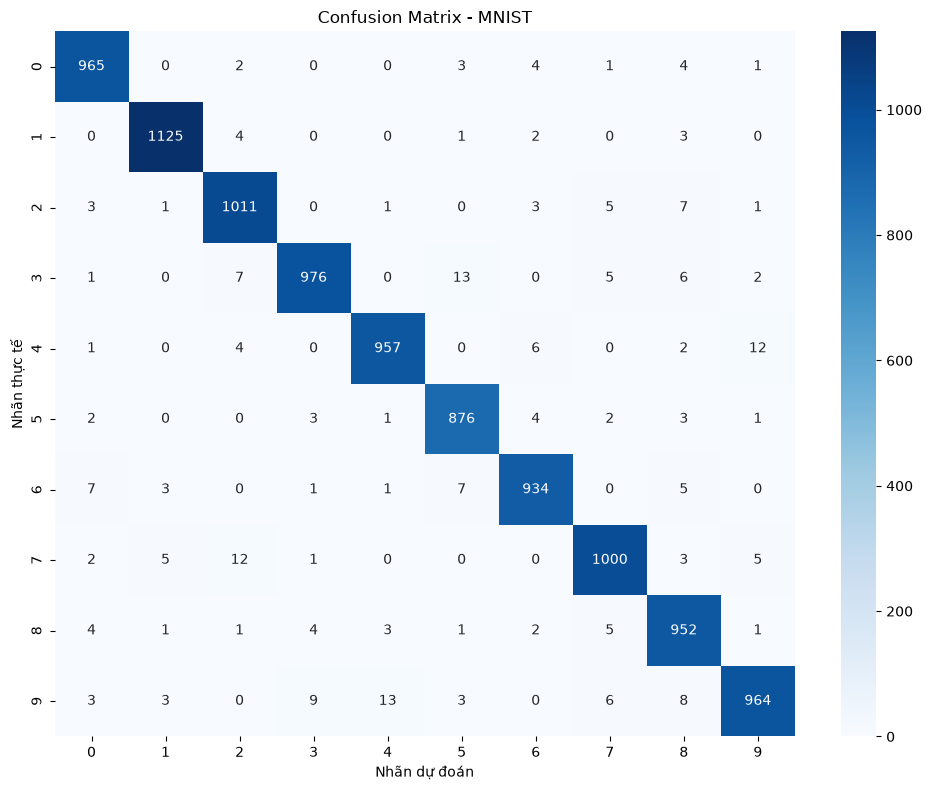

In [29]:
print("NguyenDucTinh - 6451071077")
cm = confusion_matrix(test_labels, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)
plt.title("Confusion Matrix - MNIST")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()

## Câu m: In kết quả phân lớp của 05 ảnh đầu tiên trong tập test

NguyenDucTinh - 6451071077
Ảnh 1: Nhãn dự đoán = 7, Nhãn thực tế = 7


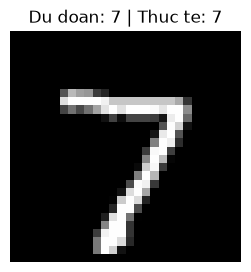

Ảnh 2: Nhãn dự đoán = 2, Nhãn thực tế = 2


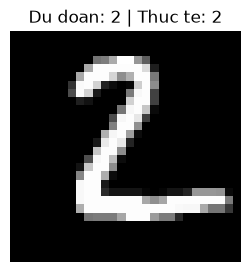

Ảnh 3: Nhãn dự đoán = 1, Nhãn thực tế = 1


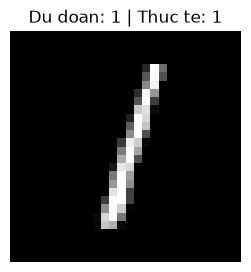

Ảnh 4: Nhãn dự đoán = 0, Nhãn thực tế = 0


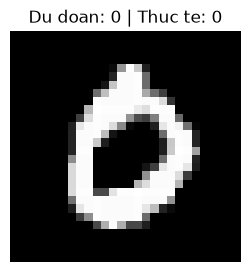

Ảnh 5: Nhãn dự đoán = 4, Nhãn thực tế = 4


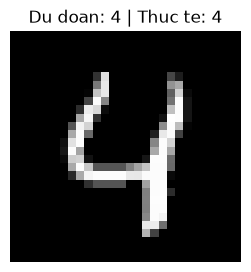

In [30]:
print("NguyenDucTinh - 6451071077")
for image_index in range(5):
    # Lấy một ảnh và thêm chiều batch bằng np.expand_dims.
    image = np.expand_dims(test_images[image_index], axis=0)

    # Dự đoán xác suất và lấy class có xác suất lớn nhất.
    probabilities = model.predict(image, verbose=0)
    predicted_label = np.argmax(probabilities, axis=1)[0]
    actual_label = test_labels[image_index]

    print(
        f"Ảnh {image_index + 1}: "
        f"Nhãn dự đoán = {predicted_label}, "
        f"Nhãn thực tế = {actual_label}"
    )

    # Hiển thị ảnh chữ số.
    plt.figure(figsize=(3, 3))
    plt.imshow(test_images[image_index], cmap="gray")
    plt.title(
        f"Du doan: {predicted_label} | Thuc te: {actual_label}"
    )
    plt.axis("off")
    plt.show()

## Câu n: In 05 kết quả đầu tiên phân lớp sai so với nhãn thực tế

NguyenDucTinh - 6451071077
Tổng số ảnh dự đoán sai: 240
Ảnh sai thứ 1 - Index: 115 | Nhãn thực tế: 4 | Nhãn dự đoán: 9


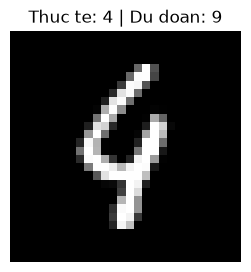

Ảnh sai thứ 2 - Index: 149 | Nhãn thực tế: 2 | Nhãn dự đoán: 9


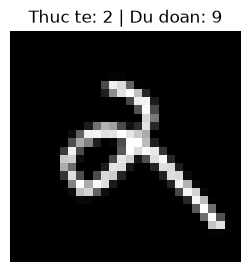

Ảnh sai thứ 3 - Index: 151 | Nhãn thực tế: 9 | Nhãn dự đoán: 8


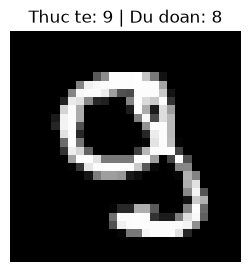

Ảnh sai thứ 4 - Index: 217 | Nhãn thực tế: 6 | Nhãn dự đoán: 5


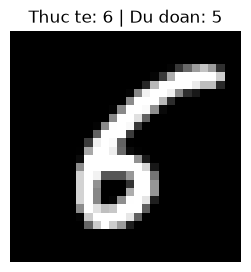

Ảnh sai thứ 5 - Index: 241 | Nhãn thực tế: 9 | Nhãn dự đoán: 8


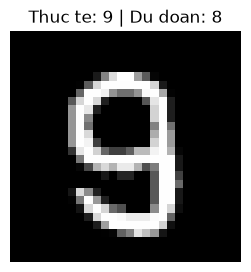

In [31]:
print("NguyenDucTinh - 6451071077")
# Tìm các vị trí mà nhãn dự đoán khác nhãn thực tế.
wrong_indices = np.where(y_pred != test_labels)[0]

print("Tổng số ảnh dự đoán sai:", len(wrong_indices))

# Lấy tối đa 5 ảnh sai đầu tiên.
first_five_wrong = wrong_indices[:5]

if len(first_five_wrong) == 0:
    print("Không có ảnh nào dự đoán sai.")
else:
    for count, image_index in enumerate(first_five_wrong, start=1):
        predicted_label = y_pred[image_index]
        actual_label = test_labels[image_index]

        print(
            f"Ảnh sai thứ {count} - Index: {image_index} | "
            f"Nhãn thực tế: {actual_label} | "
            f"Nhãn dự đoán: {predicted_label}"
        )

        plt.figure(figsize=(3, 3))
        plt.imshow(test_images[image_index], cmap="gray")
        plt.title(
            f"Thuc te: {actual_label} | Du doan: {predicted_label}"
        )
        plt.axis("off")
        plt.show()